[Python, Visually](https://johnfisher-ai.github.io/Python-Visual-Guides/) &nbsp;&rsaquo;&nbsp; [GeoPandas, Deep Dive](https://johnfisher-ai.github.io/Python-Visual-Guides/geopandas-deep-dive.html)

# Coordinate Reference Systems


## What you will be able to do

Read what a CRS says about a table's coordinates, convert a GeoDataFrame from degrees to meters with
`to_crs`, label coordinates that have no CRS with `set_crs`, and tell the two apart before a table ends
up in the wrong place.

## The idea

### The problem

The station register gives Oslo as 59.91 north and 10.75 east, in degrees. In UTM zone 33N, the system
of the forecast districts, the same place is 262,410 m east and 6,649,018 m north, and a web map stores
it as 1,196,685 and
8,379,728. All three are correct, because each pair of numbers is measured from a different origin in
a different unit, and the numbers on their own do not say which.

So every table with coordinates needs a second piece of information, the system its numbers belong
to. Without it, a join of the register with the districts compares degrees with meters and finds
nothing, as the **Spatial Joins** notebook shows. With the wrong system, every station is drawn thousands of kilometers from where it stands,
and no error says so, since any pair of numbers is a valid position somewhere. Areas and distances
depend on the system too, so the same district can be one size in one CRS and several times that size
in another.

### A formal definition

> A **coordinate reference system** (CRS) defines what a pair of coordinates means: the shape of the
> Earth it assumes (an ellipsoid and a datum), the units, the order of the axes, and for a **projected
> CRS** the formula that flattens the curved surface onto a plane. A **geographic CRS** such as WGS 84
> (EPSG:4326) gives positions as latitude and longitude in degrees. A projected CRS such as UTM zone
> 33N (EPSG:25833) gives them as meters east and north. `to_crs` converts coordinates from one CRS to
> another, and `set_crs` labels coordinates with the CRS they are already in.

### Why it works that way

A projection cannot flatten a sphere without stretching something, so each one keeps some properties
and gives up others. UTM keeps shapes and distances close to true within its zone, a band 6 degrees
of longitude wide, and stretches them more the farther a place lies from the zone's center. Web
Mercator keeps north at the top and angles true everywhere, which suits a web map's square tiles, and
in exchange inflates areas toward the poles. GeoPandas stores the CRS with each geometry column, and
pyproj does the arithmetic of converting between them.

`set_crs` changes no coordinate. It only says what the numbers already are. `to_crs` changes every
coordinate and keeps the place the same. Using one where the other was meant is an easy way to
move a whole table without noticing.

### Where this shows up

Data published by a national mapping agency usually comes in a projected CRS, here UTM zone 33N, and
data from GPS devices and web services in WGS 84. The **Measuring Distance and Area** notebook measures
in meters, and the **Spatial Joins** notebook joins two tables only once they share a CRS.

### What this notebook covers

- the CRSs of the guide's tables, and what each one says
- one place in three CRSs
- Norway drawn three ways, and Web Mercator's areas
- the order of the axes
- converting there and back
- three mistakes with `to_crs` and `set_crs`

### A first look

Before any of the detail, here is the whole idea in a few lines. There is nothing to run yet: read it,
and read the output underneath it. Everything from Setup onward is where you start running things.

```python
import geopandas as gpd
from shapely.geometry import Point

oslo = gpd.GeoSeries([Point(10.75, 59.91)], crs=4326)
print(oslo.to_crs(25833).set_precision(1).iloc[0])
print(oslo.set_crs(25833, allow_override=True).iloc[0])
```

```
POINT (262410 6649018)
POINT (10.75 59.91)
```

`to_crs` gives Oslo new numbers in meters, the same place in another system, and `set_precision(1)`
rounds them to whole meters for printing. `set_crs` keeps the numbers and only changes their label, so
the point now claims to be 10.75 m east of UTM's origin.

## Setup

Two libraries for the tables, GeoPandas and Shapely for the geometry, pyproj for the CRSs, and
Matplotlib for the maps.

- `Path` finds the guide's copy of the country outlines, when the notebook runs beside it
- `numpy` and `pandas` build the made-up register
- `geopandas` converts tables between CRSs, and the cell prints its version
- `shapely` builds the districts and writes points as text
- `CRS` describes a coordinate reference system, and `Transformer` converts single coordinates, used
  in the section on axis order
- `matplotlib.pyplot` draws Norway in three CRSs

`countries` holds the outlines of Denmark, Finland, Norway, Russia and Sweden. Made with Natural
Earth. The outlines come from Natural Earth's 1:50m map of the world's countries, which is in the
public domain. `named` is the five named stations at their real positions. `stations` is the made-up
register of 300 stations and `districts` the eight made-up forecast districts. Both are drawn from
fixed numbers, so they are the same on every run. The cell prints each table's CRS.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import shapely
from pyproj import CRS, Transformer
import matplotlib.pyplot as plt

COUNTRIES_URL = ("https://raw.githubusercontent.com/johnfisher-ai/Python-Visual-Guides/main/data/nordic-countries.geojson")
local_copy = Path("../../data/nordic-countries.geojson")
countries = gpd.read_file(local_copy if local_copy.exists() else COUNTRIES_URL)


weather_stations = pd.DataFrame({
    "name": ["Bergen", "Oslo", "Svalbard", "Tromso", "Kirkenes"],
    "latitude": [60.39, 59.91, 78.22, 69.65, 69.73],
    "longitude": [5.32, 10.75, 15.65, 18.96, 30.05],
})


def mainland_norway():
    """Norway's outline south of 74 degrees north, without Svalbard, in UTM zone 33N."""
    parts = countries[countries["ADMIN"] == "Norway"].to_crs(25833).explode()
    return parts[parts.geometry.bounds["maxy"] < 8_200_000].union_all()


def station_network(n=300, seed=2026):
    """A made-up register of weather stations on mainland Norway, one row each."""
    rng = np.random.default_rng(seed)
    land = mainland_norway()
    x_min, y_min, x_max, y_max = land.bounds
    east, north = [], []
    while len(east) < n:
        x, y = rng.uniform(x_min, x_max), rng.uniform(y_min, y_max)
        if land.contains(shapely.Point(x, y)):
            east.append(x)
            north.append(y)
    lonlat = gpd.GeoSeries(gpd.points_from_xy(east, north), crs=25833).to_crs(4326)
    return pd.DataFrame({
        "station": [f"NS{i:03d}" for i in range(1, n + 1)],
        "latitude": lonlat.y.round(4).to_numpy(), "longitude": lonlat.x.round(4).to_numpy(),
        "elevation_m": np.clip(rng.gamma(1.6, 220, n), 2, 1900).round(0).astype(int),
        "owner": rng.choice(["met", "road", "airport", "private"], n, p=[0.4, 0.3, 0.1, 0.2]),
        "installed": rng.integers(1950, 2025, n),
    })


DISTRICT_CENTERS = {"South": (8.0, 58.6), "East": (10.8, 60.5), "West": (6.0, 60.8), "Mid": (11.0, 63.6),
                    "North": (14.5, 67.0), "Far North": (19.0, 69.4), "Northeast": (25.5, 70.0),
                    "Svalbard": (16.0, 78.5)}


def forecast_districts():
    """Eight made-up forecast districts that cover Norway, in UTM zone 33N."""
    norway = countries[countries["ADMIN"] == "Norway"].to_crs(25833).geometry.iloc[0]
    centers = gpd.GeoSeries(gpd.points_from_xy(*zip(*DISTRICT_CENTERS.values())), crs=4326).to_crs(25833)
    cells = shapely.voronoi_polygons(shapely.MultiPoint(list(centers)),
                                     extend_to=shapely.box(*norway.buffer(200_000).bounds)).geoms
    names = [next(name for name, center in zip(DISTRICT_CENTERS, centers) if cell.contains(center))
             for cell in cells]
    districts = gpd.GeoDataFrame({"district": names}, geometry=[cell.intersection(norway) for cell in cells],
                                 crs=25833)
    return districts.set_index("district").loc[list(DISTRICT_CENTERS)].reset_index()


network = station_network()
stations = gpd.GeoDataFrame(
    network, geometry=gpd.points_from_xy(network["longitude"], network["latitude"]), crs=4326
)


named = gpd.GeoDataFrame(
    weather_stations,
    geometry=gpd.points_from_xy(weather_stations["longitude"], weather_stations["latitude"]),
    crs=4326,
)


districts = forecast_districts()
print("geopandas", gpd.__version__, "| stations:", stations.crs, "| districts:", districts.crs,
      "| countries:", countries.crs)

geopandas 1.2.0 | stations: EPSG:4326 | districts: EPSG:25833 | countries: EPSG:4326


## Worked examples

### What a CRS says

Each GeoDataFrame's `crs` is a pyproj `CRS` object, which can be asked about its parts.

In [2]:
for label, crs in [("countries", countries.crs), ("districts", districts.crs), ("web maps", CRS(3857))]:
    print(f"{label:10} EPSG:{crs.to_epsg()}  {crs.name}")
    print(" " * 11, "geographic:", crs.is_geographic, "| units:", crs.axis_info[0].unit_name,
          "| axes:", [axis.abbrev for axis in crs.axis_info])

countries  EPSG:4326  WGS 84
            geographic: True | units: degree | axes: ['Lat', 'Lon']
districts  EPSG:25833  ETRS89 / UTM zone 33N
            geographic: False | units: metre | axes: ['E', 'N']
web maps   EPSG:3857  WGS 84 / Pseudo-Mercator
            geographic: False | units: metre | axes: ['X', 'Y']


WGS 84 is geographic, in degrees, with latitude as its first axis. UTM zone 33N and Web Mercator are
projected, in meters. pyproj spells the unit `metre`, its own name for it.

Printed whole, a CRS describes itself in full.

In [3]:
countries.crs

<Geographic 2D CRS: EPSG:4326>
Name: WGS 84
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: World.
- bounds: (-180.0, -90.0, 180.0, 90.0)
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

The datum, World Geodetic System 1984, and the ellipsoid fix the shape of the Earth the degrees are
measured on. The area of use is the whole world.

### Oslo in three CRSs

In [4]:
oslo = named[named["name"] == "Oslo"]
for code in [4326, 25833, 3857]:
    point = oslo.to_crs(code).geometry.iloc[0]
    print(f"EPSG:{code:<6} x {point.x:>12,.2f}   y {point.y:>12,.2f}")

EPSG:4326   x        10.75   y        59.91
EPSG:25833  x   262,409.73   y 6,649,017.75
EPSG:3857   x 1,196,684.53   y 8,379,727.58


`to_crs` takes an EPSG code, and each line is Oslo. The UTM numbers are meters from an origin set so
that the zone's coordinates stay positive: 262,410 m east and 6,649,018 m north. Web Mercator's are
meters on a flattened globe, and its northing, 8,379,728, is about 1.7 million meters larger than
UTM's, because Mercator stretches distances north and south toward the poles.

### Norway drawn three ways

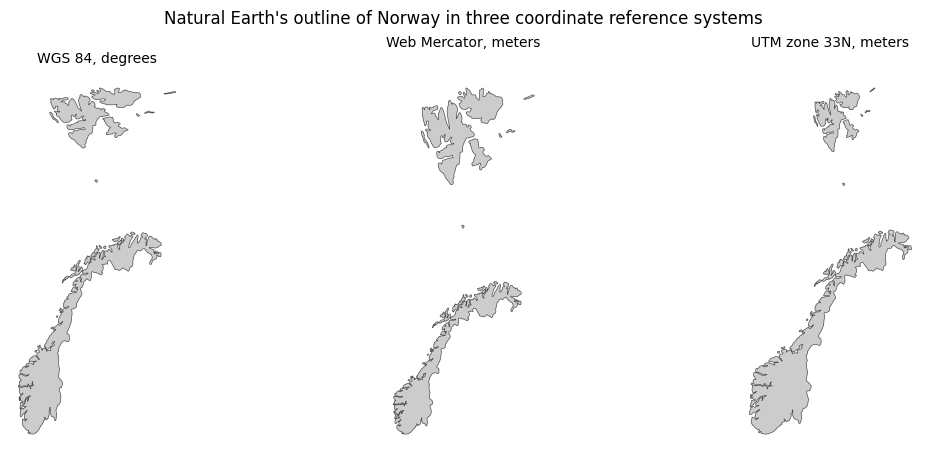

In [5]:
norway = countries[countries["ADMIN"] == "Norway"]
fig, axes = plt.subplots(1, 3, figsize=(11, 4.5), layout="constrained")
for ax, (code, title) in zip(axes, [(4326, "WGS 84, degrees"), (3857, "Web Mercator, meters"),
                                    (25833, "UTM zone 33N, meters")]):
    norway.to_crs(code).plot(ax=ax, color="0.8", edgecolor="0.3", linewidth=0.5)
    ax.set_title(title, fontsize=10)
    ax.set_axis_off()
fig.suptitle("Natural Earth's outline of Norway in three coordinate reference systems")
plt.show()

The same outline takes three shapes. In degrees, GeoPandas sets the axes' aspect so that a degree of
latitude and a degree of longitude look the right size at the middle of the outline's range of
latitudes. In Web Mercator, Svalbard at the top is drawn more than half as tall as the mainland. In UTM
zone 33N it is about a third as tall, close to its true proportion.

### Web Mercator's areas

The districts are in UTM zone 33N, whose areas are close to true here. Measured again in Web Mercator,
each district grows, and the farther north, the more.

In [6]:
sizes = pd.DataFrame({
    "district": districts["district"],
    "utm_km2": (districts.area / 1e6).round(0).astype(int),
    "mercator_km2": (districts.to_crs(3857).area / 1e6).round(0).astype(int),
})
sizes["times"] = (sizes["mercator_km2"] / sizes["utm_km2"]).round(1)
sizes

,district,utm_km2,mercator_km2,times
0,South,36056,134624,3.7
1,East,62504,259813,4.2
2,West,53904,229380,4.3
3,Mid,61575,308121,5.0
4,North,30984,197679,6.4
5,Far North,31283,244631,7.8
6,Northeast,48523,410279,8.5
7,Svalbard,62068,1664057,26.8


The South district comes out 3.7 times its size in Web Mercator, and the Svalbard district 26.8 times.
Web Mercator is for drawing tiles of a web map, and an area or a distance measured in it is wrong by
more the farther a place is from the equator, as the table shows.

### The order of the axes

The EPSG definition of WGS 84 lists latitude first, as the first cell's `axes` showed. GeoPandas and
Shapely always store x first, which for WGS 84 is the longitude, so `to_crs` on a GeoDataFrame handles
the order itself. `points_from_xy` still needs longitude first, as the **Why GeoPandas** notebook
showed. pyproj's `Transformer`, used on its own, follows the definition unless told otherwise.

In [7]:
by_definition = Transformer.from_crs(4326, 25833)
x_first = Transformer.from_crs(4326, 25833, always_xy=True)
print("by definition, given (lon, lat):", [round(v) for v in by_definition.transform(10.75, 59.91)])
print("by definition, given (lat, lon):", [round(v) for v in by_definition.transform(59.91, 10.75)])
print("always_xy, given (lon, lat):    ", [round(v) for v in x_first.transform(10.75, 59.91)])

by definition, given (lon, lat): [5955554, 1664057]
by definition, given (lat, lon): [262410, 6649018]
always_xy, given (lon, lat):     [262410, 6649018]


Given Oslo longitude first, the transformer that follows the definition reads 10.75 as a latitude and
returns numbers for somewhere else entirely, with no error. Given latitude first, or built with
`always_xy=True` and given longitude first, it returns Oslo's UTM coordinates. Pass `always_xy=True`
whenever you use a `Transformer` with coordinates in x, y order.

### Where a projected CRS applies

In [8]:
area = districts.crs.area_of_use
print(area.name[:40], "...")
print("longitudes", area.west, "to", area.east)
print("stations east of 18 degrees:", int((stations.geometry.x > 18).sum()), "of", len(stations))
print("farthest east:", round(stations.geometry.x.max(), 2))

Europe between 12°E and 18°E: Austria; C ...
longitudes 12.0 to 18.01
stations east of 18 degrees: 64 of 300
farthest east: 30.58


UTM zone 33N is defined for longitudes 12 to 18 degrees east (18.01 in pyproj's record), and 64 of the
register's stations lie east of 18 degrees, the farthest at 30.58. pyproj still converts them, and the farther a place
is from the zone, the more its distances are stretched, which the **Measuring Distance and Area**
notebook measures.

### There and back

Converting to meters and back again returns the original coordinates.

In [9]:
round_trip = stations.to_crs(25833).to_crs(4326)
shift = np.maximum((round_trip.geometry.x - stations.geometry.x).abs(),
                   (round_trip.geometry.y - stations.geometry.y).abs()).max()
print("less than a billionth of a degree:", shift < 1e-9)

less than a billionth of a degree: True


The largest change across 300 stations is less than a billionth of a degree, about a tenth of a
millimeter on the ground, so a table can be converted as often as a task needs.

## Your turn

Five tasks. Write your answer in the cell under each task and run it.

Try a task before you look at its answer. Reading a solution teaches you much less than
getting there yourself, even slowly.

When you are ready: [**open the solutions notebook**](https://colab.research.google.com/github/johnfisher-ai/Python-Visual-Guides/blob/main/notebooks/geopandas-deep-dive/04-coordinate-reference-systems-solutions.ipynb).

**1.** Make the CRS with EPSG code 3035, a projection used across Europe, and print its name, the unit of its first axis, whether it is projected, and the order of its axes.

In [10]:
# your code here

**2.** Convert `named` to UTM zone 33N, and print each station's name with its easting and northing in kilometers, rounded to a whole number.

In [11]:
# your code here

**3.** Measure Norway's area in EPSG:3035, which keeps areas true, and print it in square kilometers beside the 386,897 km² that UTM zone 33N gives.

In [12]:
# your code here

**4.** Count the made-up stations that lie west of 12 degrees east, the other edge of UTM zone 33N's area of use.

In [13]:
# your code here

**5.** A file gives Bergen's position as 297,230 m east and 6,700,510 m north in UTM zone 32N, EPSG:25832. Make a GeoSeries from those numbers, give it that CRS, and print its longitude and latitude, rounded to two places.

In [14]:
# your code here

## Common errors

### `ValueError: Cannot transform naive geometries.  Please set a crs on the object first.`

A table built from coordinates without `crs=` has no CRS, which GeoPandas calls naive.

In [15]:
no_crs = gpd.GeoDataFrame(
    weather_stations, geometry=gpd.points_from_xy(weather_stations["longitude"], weather_stations["latitude"])
)
print("CRS:", no_crs.crs)
no_crs.to_crs(25833)

CRS: None


ValueError: Cannot transform naive geometries.  Please set a crs on the object first.

`to_crs` needs to know what the numbers are now before it can convert them. These numbers are degrees,
so label them with `set_crs`, and then convert.

In [16]:
labeled = no_crs.set_crs(4326)
print(labeled.crs, "->", labeled.to_crs(25833).crs)

EPSG:4326 -> EPSG:25833


### `ValueError: The GeoSeries already has a CRS which is not equal to the passed CRS.`

In [17]:
stations.set_crs(25833)

ValueError: The GeoSeries already has a CRS which is not equal to the passed CRS. Specify 'allow_override=True' to allow replacing the existing CRS without doing any transformation. If you actually want to transform the geometries, use 'GeoSeries.to_crs' instead.

`set_crs` labels coordinates, and the stations already have a label, EPSG:4326. The rest of the
message offers two ways out: `allow_override=True` to replace the label, or `to_crs` to convert. Here
the stations are in degrees and the goal is meters, so `to_crs` is the one meant.

### No error, and 300 stations on the equator

In [18]:
relabeled = stations.set_crs(25833, allow_override=True)
print("first station, relabeled:", shapely.to_wkt(relabeled.geometry.iloc[0], rounding_precision=4))
print("the same, as degrees:   ", shapely.to_wkt(relabeled.to_crs(4326).geometry.iloc[0], rounding_precision=4))
found = gpd.sjoin(relabeled.to_crs(4326), countries[["ADMIN", "geometry"]], how="left")
print("stations in a country:", found["ADMIN"].notna().sum())

first station, relabeled: POINT (10.6233 61.1793)
the same, as degrees:    POINT (10.5114 0.0006)
stations in a country: 0


`allow_override=True` replaced the label and kept the numbers, so 10.62 and 61.18 are now read as
meters from UTM's origin, which lies on the equator. Converted back to degrees, the first station sits
at latitude 0.0006, and none of the 300 falls in any of the five countries. `to_crs` converts the
numbers and keeps every station in Norway.

In [19]:
converted = stations.to_crs(25833)
print("first station, converted:", shapely.to_wkt(converted.geometry.iloc[0], rounding_precision=0))
found = gpd.sjoin(converted.to_crs(4326), countries[["ADMIN", "geometry"]], how="left")
print("stations in a country:", found["ADMIN"].notna().sum())

first station, converted: POINT (264741 6790637)
stations in a country: 300


## Recap

- You can read a CRS's name, units, axis order and area of use.
- You can convert a GeoDataFrame between CRSs with `to_crs`, by EPSG code.
- You can label coordinates that have no CRS with `set_crs`, and tell when `to_crs` was meant
  instead.
- You can explain why Web Mercator's areas grow toward the poles.
- You can build a pyproj `Transformer` that takes longitude first.

## What is next

The **Reading and Writing Files** notebook saves GeoDataFrames to GeoJSON, GeoPackage and Shapefile,
and reads them back with their CRS.

---

&#8592; **Previous:** [The GeoDataFrame](https://colab.research.google.com/github/johnfisher-ai/Python-Visual-Guides/blob/main/notebooks/geopandas-deep-dive/03-the-geodataframe.ipynb)  &nbsp;·&nbsp;  [GeoPandas, Deep Dive Notebooks](https://johnfisher-ai.github.io/Python-Visual-Guides/geopandas-deep-dive.html)
